# 05_Challenger_SHAP — Challenger LightGBM et explicabilité SHAP

**Projet :** Credit Risk Scorecard · **Phase 4** — sous-ensemble 4a · Données : Home Credit Default Risk (Kaggle).

- Le modèle est entraîné par `scripts/train_challenger.py` (à lancer avant ce notebook) ; le notebook **relit les artefacts** (`models/`, `output/tables/challenger_metrics.json`) et n'entraîne rien.
- Variables : les candidates du catalogue (D16), valeurs brutes, manquants laissés à LightGBM, colonnes texte en `category` (modalités figées sur le train).
- Train pour l'apprentissage, validation pour l'early stopping (AUC) et le choix de variante ; **le test reste scellé (D15)**.
- Le notebook ouvre la base **en lecture seule** ; il n'écrit que les figures `output/05_*.png`.

In [1]:
# --- Setup : vérification du répertoire de travail, connexion DuckDB en lecture seule ---
import os
import sys
from pathlib import Path

cwd = Path.cwd()
# Jupyter / VS Code lancent le noyau dans notebooks/ : on remonte d'un niveau si c'est le cas.
if cwd.name == "notebooks" and (cwd.parent / "scripts" / "config.py").is_file():
    os.chdir(cwd.parent)
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name != "credit-risk-scorecard" or not (PROJECT_ROOT / "scripts" / "config.py").is_file():
    raise RuntimeError(
        f"Répertoire de travail inattendu : {PROJECT_ROOT}. "
        "Lancer le notebook depuis la racine credit-risk-scorecard/ (ou depuis notebooks/)."
    )
sys.path.insert(0, str(PROJECT_ROOT / "scripts"))

import hashlib

import duckdb
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from build_feature_catalog import CAND, CATALOG
from config import DB_PATH, FIGURES_DIR
from make_splits import load_split

if not DB_PATH.exists():
    raise FileNotFoundError(f"{DB_PATH} introuvable.")
con = duckdb.connect(str(DB_PATH), read_only=True)

# Style des figures : identique aux notebooks 00 et 01
BLUE, INK, INK2, GRID, GREY = "#2a78d6", "#0b0b0b", "#52514e", "#e4e3df", "#a3a29d"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 11, "font.size": 9,
})
print("Racine :", PROJECT_ROOT.name)
print(f"Python {sys.version.split()[0]} · duckdb {duckdb.__version__} · pandas {pd.__version__} · matplotlib {matplotlib.__version__}")

Racine : credit-risk-scorecard
Python 3.13.15 · duckdb 1.5.5 · pandas 3.0.6 · matplotlib 3.11.2


In [2]:
# --- Artefacts du challenger (produits par scripts/train_challenger.py) ---
import json

from IPython.display import Image
from sklearn.metrics import roc_auc_score

import train_challenger as tc

for p in (tc.MODEL_PATH, tc.MODEL_NO_EXT_PATH, tc.CATEGORIES_PATH, tc.VALID_SCORES_PATH, tc.METRICS_PATH, tc.IMPORTANCE_PATH):
    if not p.exists():
        raise FileNotFoundError(f"{p} introuvable : lancer d'abord scripts/train_challenger.py")
summary = json.loads(tc.METRICS_PATH.read_text(encoding="utf-8"))
booster, categories = tc.load_artefacts()
print(f"lightgbm {summary['lightgbm_version']} · {summary['n_features']} variables ({len(categories)} catégorielles) · "
      f"{booster.num_trees()} arbres")

lightgbm 4.7.0 · 200 variables (14 catégorielles) · 912 arbres


## 1. Paramètres et choix de la variante

Paramètres modérés, sans optimisation poussée ; apprentissage déterministe (`seed`, `deterministic`, `force_col_wise`, `num_threads` fixe).
Deux variantes comparées sur la validation : **sans pondération** et **`scale_pos_weight` = négatifs / positifs**.
Règle de choix : AUC de validation la plus haute, sauf si le Brier de cette variante dépasse de plus de 10 % celui de l'autre (la PD doit rester calibrée, §8).

In [3]:
params = {k: v for k, v in summary["params"].items() if k not in ("objective", "metric", "verbosity")}
display(pd.DataFrame({"paramètre": list(params), "valeur": [str(v) for v in params.values()]}).style.hide(axis="index"))

rows = []
for name, r in summary["variants"].items():
    for s in ("train", "valid"):
        rows.append({"variante": name, "échantillon": s, "best_iteration": r["best_iteration"],
                     **{k.upper(): r[s][k] for k in ("auc", "gini", "ks", "brier")}, "PD moyenne": r[s]["mean_pd"]})
variants = pd.DataFrame(rows)
display(variants.style.format({"AUC": "{:.4f}", "GINI": "{:.4f}", "KS": "{:.4f}", "BRIER": "{:.4f}", "PD moyenne": "{:.4f}"})
        .hide(axis="index"))
display(Markdown(f"**Variante retenue : `{summary['chosen_variant']}`** — {summary['choice_reason']}"))

paramètre,valeur
learning_rate,0.03
num_leaves,31
min_child_samples,100
feature_fraction,0.7
bagging_fraction,0.8
bagging_freq,1
lambda_l2,5.0
seed,42
deterministic,True
force_col_wise,True


variante,échantillon,best_iteration,AUC,GINI,KS,BRIER,PD moyenne
unweighted,train,912,0.8808,0.7615,0.5948,0.0568,0.0806
unweighted,valid,912,0.7851,0.5702,0.4322,0.0659,0.0797
scale_pos_weight,train,891,0.8910,0.7821,0.6225,0.1474,0.3508
scale_pos_weight,valid,891,0.7847,0.5694,0.4298,0.1619,0.3507


**Variante retenue : `unweighted`** — unweighted a l'AUC de validation la plus haute (0.7851 vs 0.7847) sans dégradation du Brier au-delà de 110% (0.0659 vs 0.1619).

## 2. Performance de la variante retenue

Contrôle : les PD de validation enregistrées (`models/lgbm_valid_scores.parquet`) sont recalculées avec `predict_frame()`, la fonction qui servira à scorer le test.

In [4]:
cols = ["SK_ID_CURR", "TARGET", *booster.feature_name()]
valid = load_split(con, "valid", cols)
saved = pd.read_parquet(tc.VALID_SCORES_PATH)
recomputed = tc.predict_frame(valid)
gap = float(np.max(np.abs(saved["pd"].to_numpy() - recomputed["pd"].to_numpy())))
if not saved["SK_ID_CURR"].equals(recomputed["SK_ID_CURR"]) or gap > 1e-9:
    raise RuntimeError(f"Scores enregistrés ≠ predict_frame (écart {gap:.2e}).")
auc_check = roc_auc_score(valid["TARGET"], saved["pd"])

m = summary["metrics"]
perf = pd.DataFrame({s: {k.upper(): m[s][k] for k in ("auc", "gini", "ks", "brier", "mean_pd", "default_rate")} for s in ("train", "valid")})
perf.index = ["AUC", "Gini", "KS", "Brier", "PD moyenne", "Taux de défaut observé"]
perf["écart train − valid"] = perf["train"] - perf["valid"]
display(perf.style.format("{:.4f}"))
print(f"predict_frame conforme (écart max {gap:.1e}) ; AUC valid recalculée : {auc_check:.4f}")

,train,valid,écart train − valid
AUC,0.8808,0.7851,0.0957
Gini,0.7615,0.5702,0.1914
KS,0.5948,0.4322,0.1626
Brier,0.0568,0.0659,-0.0090
PD moyenne,0.0806,0.0797,0.0009
Taux de défaut observé,0.0807,0.0807,0.0000


predict_frame conforme (écart max 0.0e+00) ; AUC valid recalculée : 0.7851


In [5]:
display(Markdown(f"""
- Arrêt à **{summary['best_iteration']} itérations** (plafond {summary['params']['num_boost_round_max']}, patience {summary['params']['early_stopping_rounds']}).
- Validation : AUC **{m['valid']['auc']:.4f}**, Gini {m['valid']['gini']:.4f}, KS {m['valid']['ks']:.4f}, Brier {m['valid']['brier']:.4f} ;
  PD moyenne {m['valid']['mean_pd']:.4f} pour un taux observé de {m['valid']['default_rate']:.4f}.
- Écart d'AUC train − validation : {m['train']['auc'] - m['valid']['auc']:.4f}. Le modèle mémorise une partie du train ;
  la mesure à retenir est celle de la validation, elle-même légèrement optimiste (early stopping et choix de variante faits dessus) :
  la mesure finale se fera sur le test (D15).
"""))


- Arrêt à **912 itérations** (plafond 3000, patience 100).
- Validation : AUC **0.7851**, Gini 0.5702, KS 0.4322, Brier 0.0659 ;
  PD moyenne 0.0797 pour un taux observé de 0.0807.
- Écart d'AUC train − validation : 0.0957. Le modèle mémorise une partie du train ;
  la mesure à retenir est celle de la validation, elle-même légèrement optimiste (early stopping et choix de variante faits dessus) :
  la mesure finale se fera sur le test (D15).


## 3. Ablation `EXT_SOURCE`

La variante retenue est réentraînée sans **aucune** variable `EXT_SOURCE` (les trois scores externes et les deux variables dérivées `APP_EXT_SOURCE_*`), mêmes paramètres.

In [6]:
ab = summary["ablation_ext_source"]
abl = pd.DataFrame({
    "modèle": ["avec EXT_SOURCE", "sans EXT_SOURCE"],
    "variables": [summary["n_features"], ab["n_features"]],
    "best_iteration": [summary["best_iteration"], ab["best_iteration"]],
    "AUC valid": [m["valid"]["auc"], ab["valid"]["auc"]],
    "Gini valid": [m["valid"]["gini"], ab["valid"]["gini"]],
    "KS valid": [m["valid"]["ks"], ab["valid"]["ks"]],
    "Brier valid": [m["valid"]["brier"], ab["valid"]["brier"]],
})
display(abl.style.format({c: "{:.4f}" for c in ("AUC valid", "Gini valid", "KS valid", "Brier valid")}).hide(axis="index"))
display(Markdown(f"""
Variables retirées : {", ".join(f"`{c}`" for c in ab["removed_features"])}.
Sans elles, l'AUC de validation passe de {m['valid']['auc']:.4f} à {ab['valid']['auc']:.4f}
(**Δ AUC {ab['delta_valid_auc']:+.4f}**, Δ Gini {ab['delta_valid_gini']:+.4f}) : la dépendance aux scores externes est chiffrée,
le modèle conserve un pouvoir discriminant sur les seules données de demande et d'historique.
"""))

modèle,variables,best_iteration,AUC valid,Gini valid,KS valid,Brier valid
avec EXT_SOURCE,200,912,0.7851,0.5702,0.4322,0.0659
sans EXT_SOURCE,195,698,0.7617,0.5234,0.3865,0.0677



Variables retirées : `EXT_SOURCE_1`, `EXT_SOURCE_2`, `EXT_SOURCE_3`, `APP_EXT_SOURCE_MEAN`, `APP_EXT_SOURCE_NB_MISSING`.
Sans elles, l'AUC de validation passe de 0.7851 à 0.7617
(**Δ AUC -0.0234**, Δ Gini -0.0467) : la dépendance aux scores externes est chiffrée,
le modèle conserve un pouvoir discriminant sur les seules données de demande et d'historique.


## 4. Importance des variables (gain LightGBM)

Gain total des divisions par variable (`output/tables/lgbm_feature_importance.csv`) ; 20 premières variables.

In [7]:
fi = pd.read_csv(tc.IMPORTANCE_PATH)
display(fi.head(20).style.format({"gain": "{:,.0f}", "gain_share_pct": "{:.2f}"}).hide(axis="index"))
print(f"Variables jamais utilisées (gain nul) : {int((fi['gain'] == 0).sum())} / {len(fi)}")

feature,gain,split,gain_share_pct,rank
APP_EXT_SOURCE_MEAN,"111,008",570,21.05,1
ORGANIZATION_TYPE,"42,399",2727,8.04,2
EXT_SOURCE_3,"21,978",626,4.17,3
EXT_SOURCE_2,"17,098",503,3.24,4
APP_CREDIT_TERM_MONTHS,"15,847",808,3.01,5
EXT_SOURCE_1,"10,758",538,2.04,6
APP_CREDIT_GOODS_RATIO,"10,165",373,1.93,7
OCCUPATION_TYPE,"10,144",654,1.92,8
PREV_MEAN_CREDIT_APPLICATION_RATIO,"9,437",460,1.79,9
BUR_YEARS_SINCE_LAST_CREDIT,"9,268",570,1.76,10


Variables jamais utilisées (gain nul) : 21 / 200


## 5. SHAP — importance globale

`TreeExplainer` sur un échantillon fixe de 5 000 lignes de validation (tirage `RANDOM_STATE` = 42). Contributions en **log-odds** : une valeur positive augmente la PD.
Contrôle d'additivité : base + somme des contributions = sortie brute du modèle.

.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Échantillon : 5,000 lignes · additivité : écart max 3.3e-14 · figures : 05_shap_bar.png, 05_shap_beeswarm.png, 05_shap_dependence.png, 05_shap_waterfall_low.png, 05_shap_waterfall_median.png, 05_shap_waterfall_high.png


feature,mean_abs_shap,share_pct,rank
APP_EXT_SOURCE_MEAN,0.3890,11.43,1
PREV_MEAN_CNT_PAYMENT,0.1104,3.24,2
APP_CREDIT_TERM_MONTHS,0.1000,2.94,3
ORGANIZATION_TYPE,0.0991,2.91,4
APP_CREDIT_GOODS_RATIO,0.0953,2.80,5
AMT_ANNUITY,0.0876,2.57,6
EXT_SOURCE_3,0.0865,2.54,7
EXT_SOURCE_1,0.0863,2.53,8
PREV_MEAN_CREDIT_APPLICATION_RATIO,0.0814,2.39,9
OCCUPATION_TYPE,0.0743,2.18,10


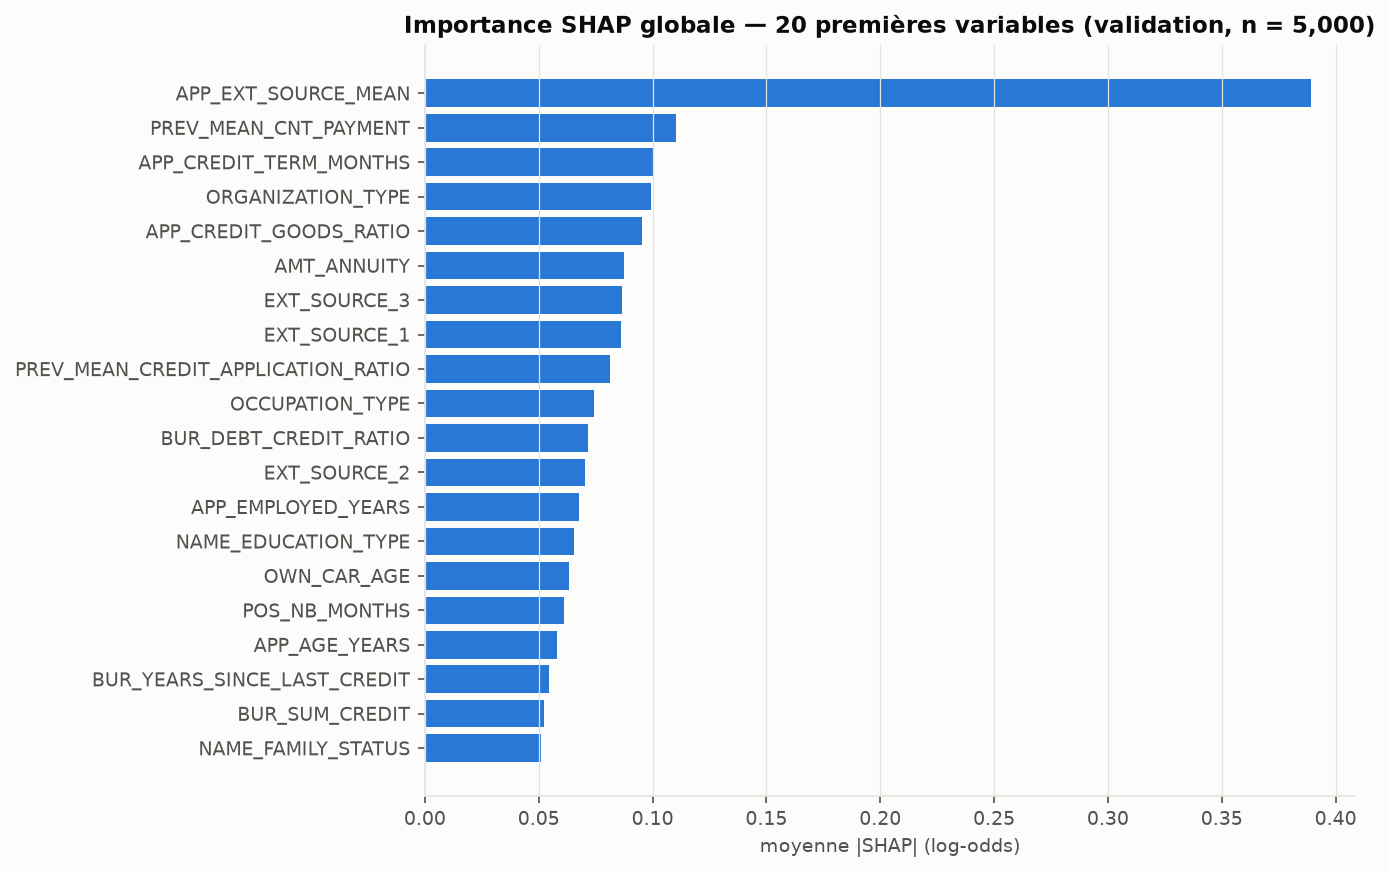

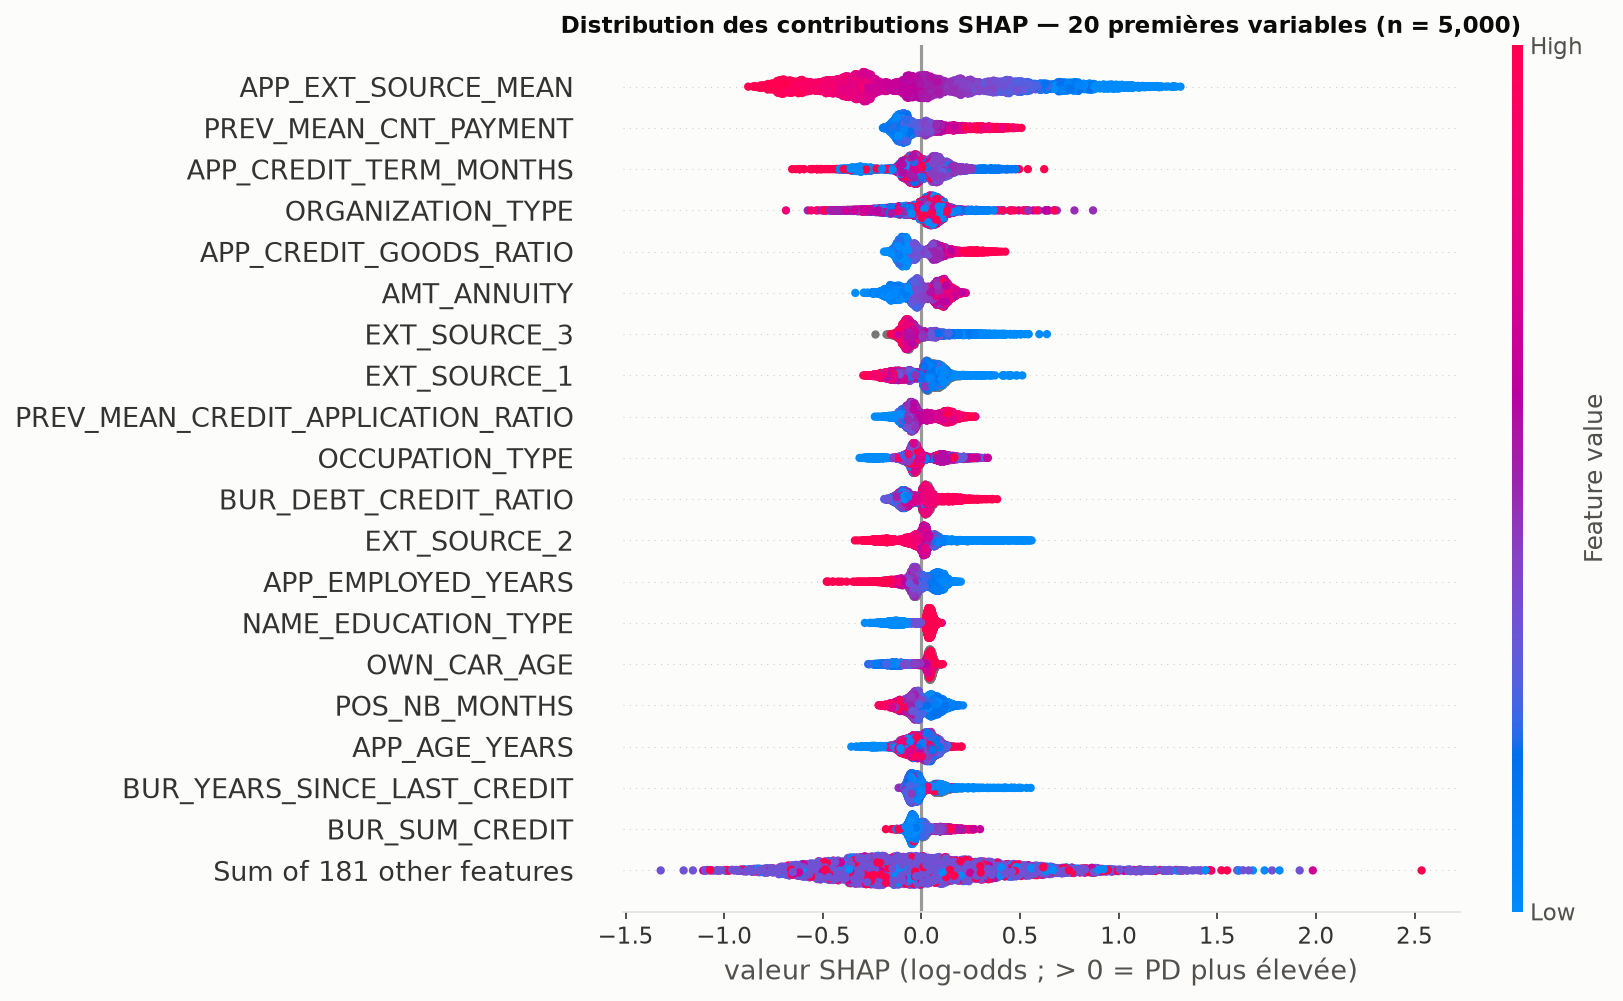

In [8]:
plt.rcParams.update(tc.PLOT_STYLE)
X_va = tc.prepare_X(valid, booster.feature_name(), categories)
X_s = tc.shap_sample(X_va)
expl, add_gap = tc.compute_shap(booster, X_s)
pd_s = booster.predict(X_s)
imp = tc.shap_importance(expl)
if imp["feature"].head(5).tolist() != summary["shap"]["top5"]:
    raise RuntimeError("Top 5 SHAP différent de celui enregistré par le script.")
paths = tc.make_shap_figures(expl, X_s, pd_s, imp, categories)
print(f"Échantillon : {len(X_s):,} lignes · additivité : écart max {add_gap:.1e} · figures : {', '.join(p.name for p in paths)}")
display(imp.head(10).style.format({"mean_abs_shap": "{:.4f}", "share_pct": "{:.2f}"}).hide(axis="index"))
display(Image(filename=str(FIGURES_DIR / "05_shap_bar.png")))
display(Image(filename=str(FIGURES_DIR / "05_shap_beeswarm.png")))

In [9]:
top20_shap, top20_gain = set(imp["feature"].head(20)), set(fi["feature"].head(20))
ext_share = imp.loc[imp["feature"].str.contains("EXT_SOURCE"), "share_pct"].sum()
display(Markdown(f"""
- `{imp['feature'].iloc[0]}` concentre {imp['share_pct'].iloc[0]:.1f} % de la moyenne |SHAP| totale, loin devant
  `{imp['feature'].iloc[1]}` ({imp['share_pct'].iloc[1]:.1f} %) ; l'ensemble des variables `EXT_SOURCE` en pèse {ext_share:.1f} %.
- Les 10 premières variables représentent {imp['share_pct'].head(10).sum():.1f} % du total : le reste du signal est réparti sur de nombreuses variables.
- {len(top20_shap & top20_gain)} variables sur 20 sont communes aux classements SHAP et gain.
"""))


- `APP_EXT_SOURCE_MEAN` concentre 11.4 % de la moyenne |SHAP| totale, loin devant
  `PREV_MEAN_CNT_PAYMENT` (3.2 %) ; l'ensemble des variables `EXT_SOURCE` en pèse 18.8 %.
- Les 10 premières variables représentent 35.5 % du total : le reste du signal est réparti sur de nombreuses variables.
- 17 variables sur 20 sont communes aux classements SHAP et gain.


## 6. SHAP — dépendances des 5 premières variables

Pour les variables numériques : contribution SHAP en fonction de la valeur (manquants en gris). Pour une variable catégorielle : contribution moyenne par modalité.
Le sens observé est comparé au sens attendu du catalogue (Phase 2) via la corrélation de Spearman entre valeur et contribution.

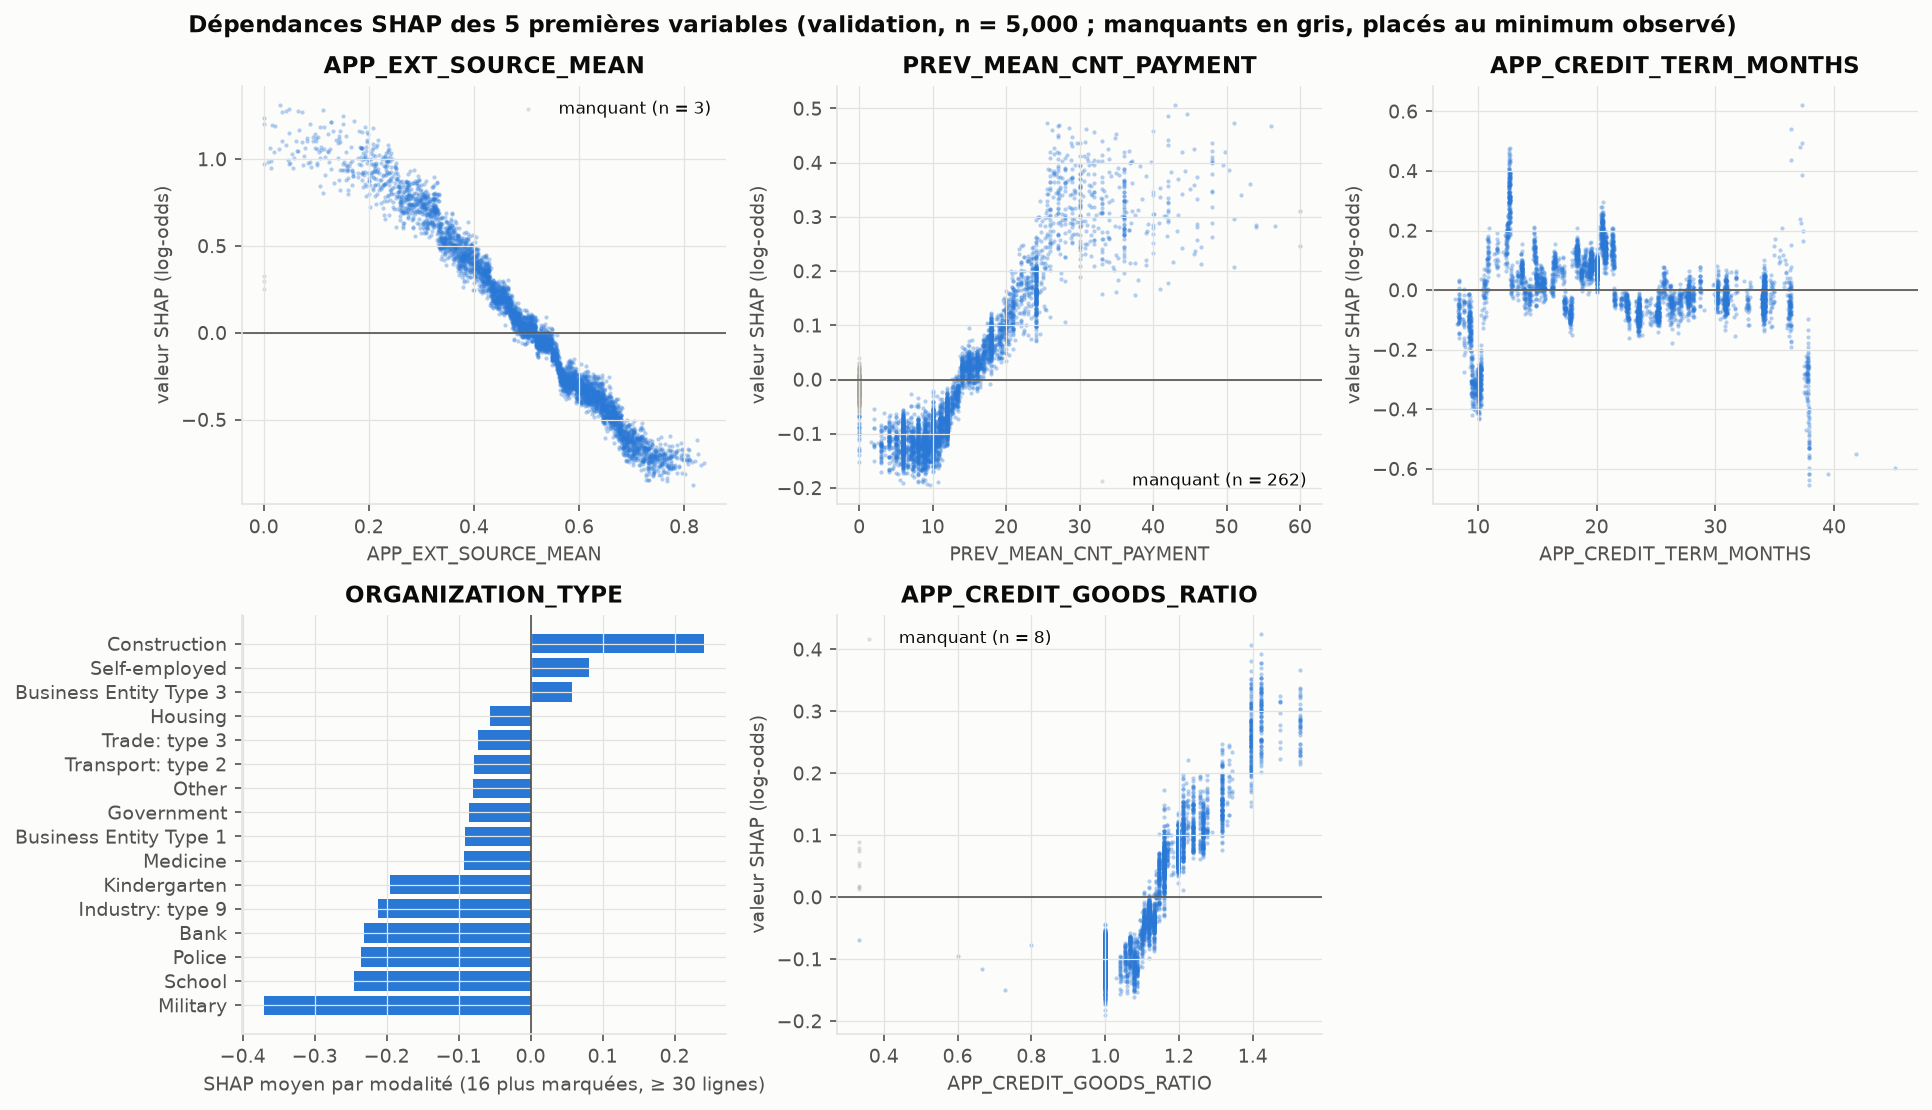

variable,sens attendu (catalogue),Spearman valeur/SHAP,sens observé,manquants dans l'échantillon
APP_EXT_SOURCE_MEAN,↓,-0.99,↓,3
PREV_MEAN_CNT_PAYMENT,indéterminé,0.92,↑,262
APP_CREDIT_TERM_MONTHS,indéterminé,-0.16,↓,0
ORGANIZATION_TYPE,indéterminé,—,catégorielle,0
APP_CREDIT_GOODS_RATIO,↑,0.92,↑,8


- Relation quasi monotone (|ρ| ≥ 0,8) : `APP_EXT_SOURCE_MEAN`, `PREV_MEAN_CNT_PAYMENT`, `APP_CREDIT_GOODS_RATIO`.
- Relation non monotone (|ρ| < 0,5), que la scorecard linéaire en WoE ne capte que par classes : `APP_CREDIT_TERM_MONTHS`.
- Sens observé conforme au sens attendu du catalogue : `APP_EXT_SOURCE_MEAN`, `APP_CREDIT_GOODS_RATIO` (les autres variables avaient un sens « indéterminé » a priori).

In [10]:
display(Image(filename=str(FIGURES_DIR / "05_shap_dependence.png")))
rows = []
for f in imp["feature"].head(tc.N_DEPENDENCE):
    j = list(X_s.columns).index(f)
    x, v = expl.data[:, j], expl.values[:, j]
    ok = ~np.isnan(x)
    rho = np.nan if f in categories else pd.Series(x[ok]).corr(pd.Series(v[ok]), method="spearman")
    observed = "catégorielle" if f in categories else ("↑" if rho > 0 else "↓")
    rows.append({"variable": f, "sens attendu (catalogue)": CATALOG[f][2], "Spearman valeur/SHAP": rho,
                 "sens observé": observed, "manquants dans l'échantillon": int((~ok).sum())})
dep = pd.DataFrame(rows)
display(dep.style.format({"Spearman valeur/SHAP": "{:.2f}"}, na_rep="—").hide(axis="index"))
num = dep.dropna(subset=["Spearman valeur/SHAP"])
mono = num.loc[num["Spearman valeur/SHAP"].abs() >= 0.8, "variable"].tolist()
non_mono = num.loc[num["Spearman valeur/SHAP"].abs() < 0.5, "variable"].tolist()
agree = [r.variable for r in num.itertuples() if r[2] in ("↑", "↓") and r[2] == r[4]]
display(Markdown(
    f"- Relation quasi monotone (|ρ| ≥ 0,8) : {', '.join(f'`{v}`' for v in mono) or 'aucune'}.\n"
    f"- Relation non monotone (|ρ| < 0,5), que la scorecard linéaire en WoE ne capte que par classes : "
    f"{', '.join(f'`{v}`' for v in non_mono) or 'aucune'}.\n"
    f"- Sens observé conforme au sens attendu du catalogue : {', '.join(f'`{v}`' for v in agree) or 'aucune'} "
    f"(les autres variables avaient un sens « indéterminé » a priori)."
))

## 7. SHAP — cas individuels

Trois demandes de l'échantillon : PD la plus basse (profil d'accord), PD médiane (cas limite) et PD la plus haute (profil de refus). Base = sortie moyenne du modèle en log-odds.

**PD la plus basse** — SK_ID_CURR 305140, PD 0.0029. Trois contributions les plus fortes : `APP_EXT_SOURCE_MEAN` -0.48 ; `ORGANIZATION_TYPE` -0.36 ; `EXT_SOURCE_2` -0.20.

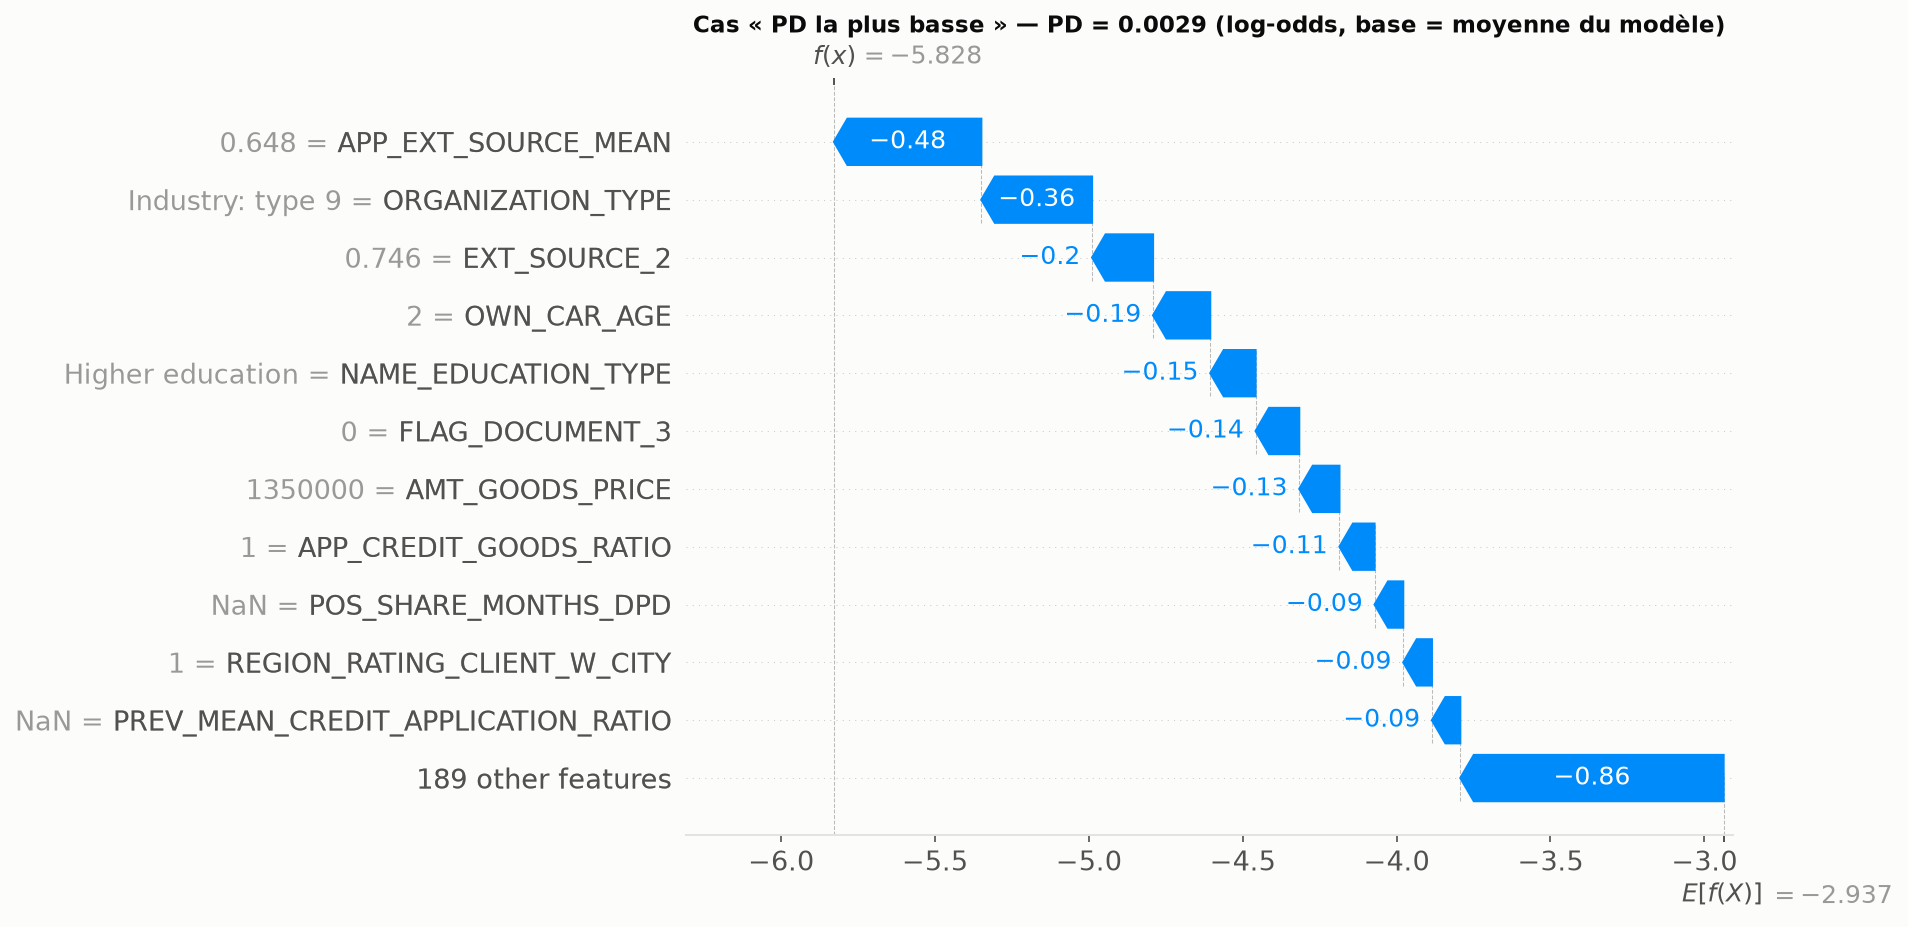

**PD médiane** — SK_ID_CURR 414901, PD 0.0453. Trois contributions les plus fortes : `OWN_CAR_AGE` -0.20 ; `BUR_SUM_CREDIT` +0.19 ; `AMT_ANNUITY` +0.15.

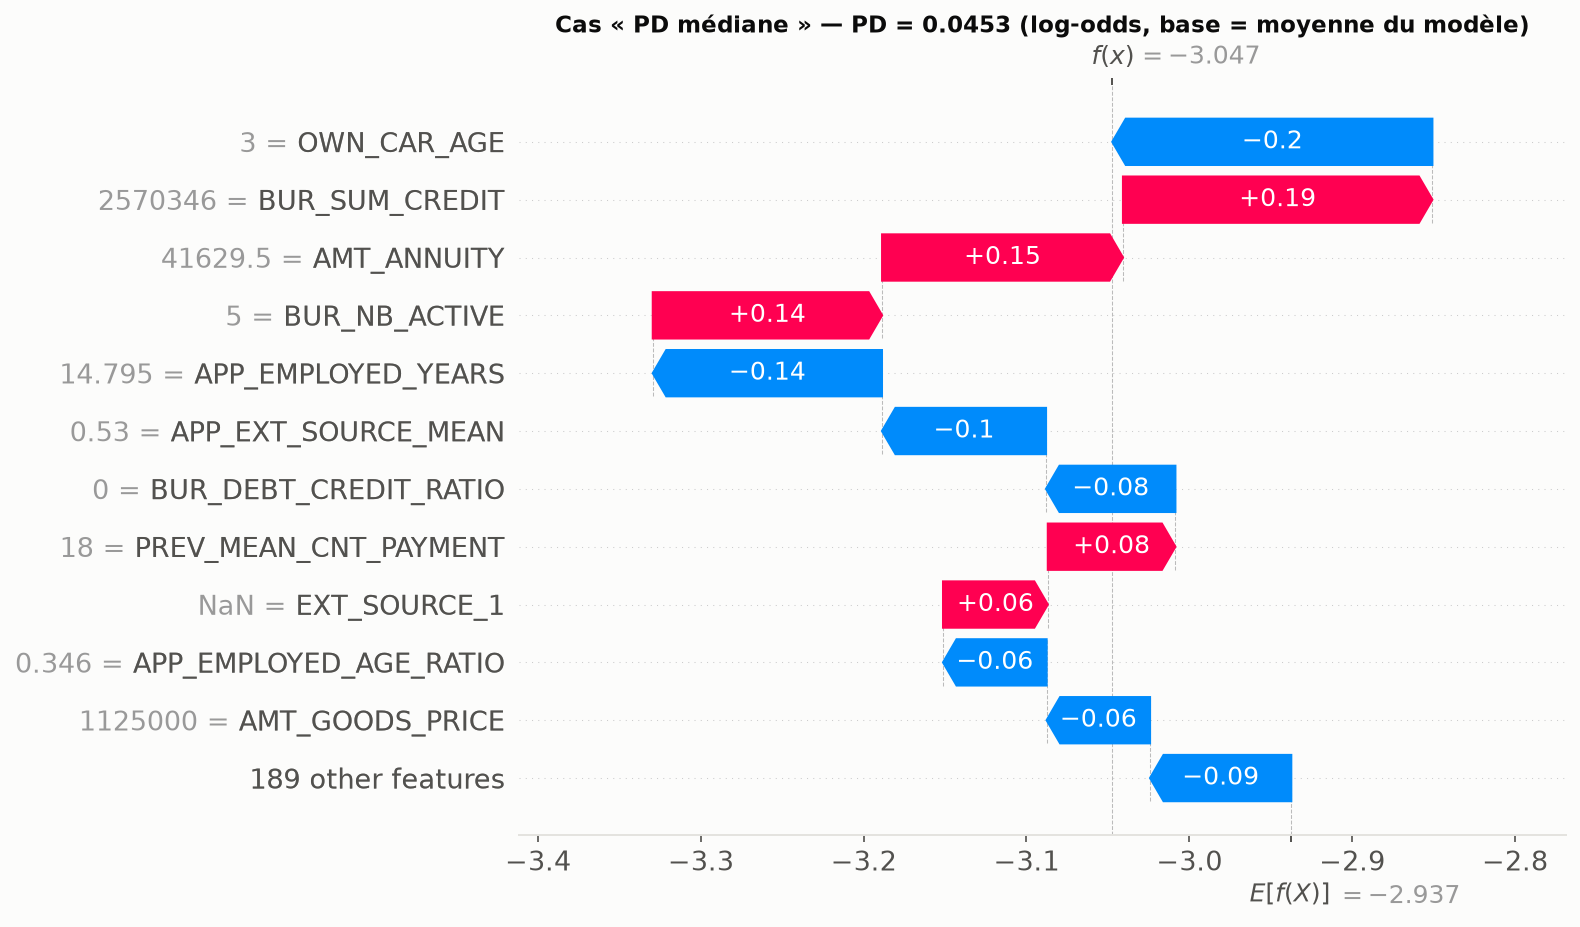

**PD la plus haute** — SK_ID_CURR 348073, PD 0.7508. Trois contributions les plus fortes : `APP_EXT_SOURCE_MEAN` +0.68 ; `BUR_YEARS_SINCE_LAST_CREDIT` +0.47 ; `PREV_MEAN_CNT_PAYMENT` +0.27.

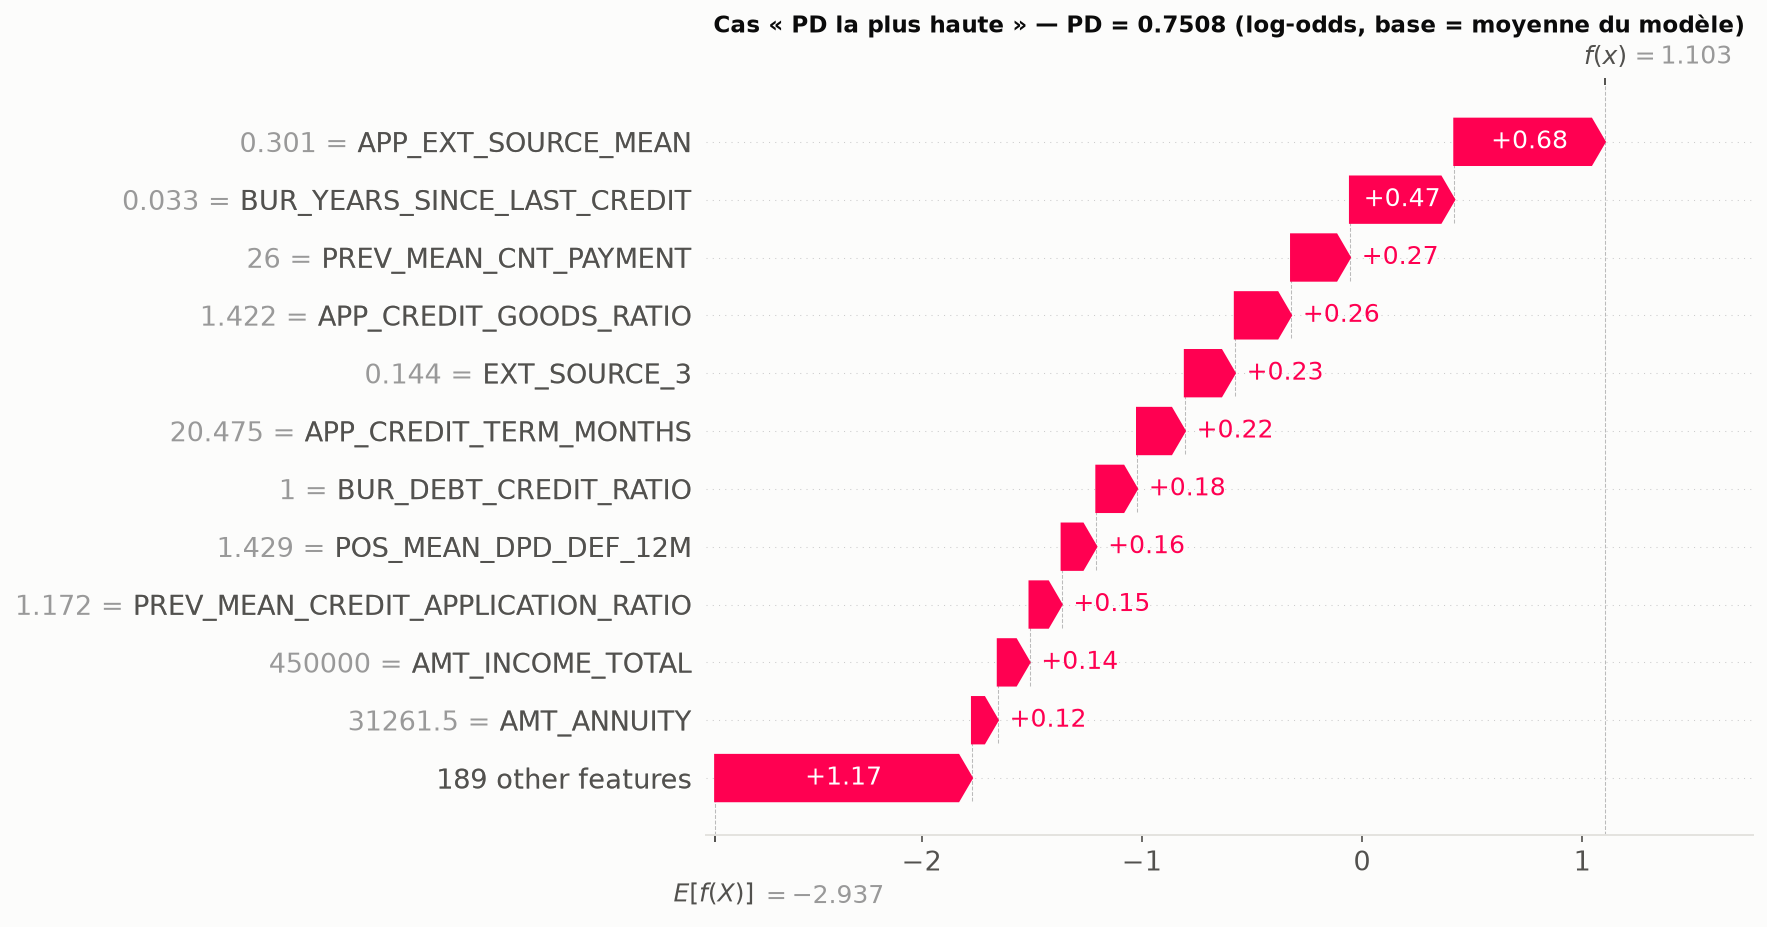

In [11]:
labels = {"low": "PD la plus basse", "median": "PD médiane", "high": "PD la plus haute"}
for key, case in summary["shap"]["cases"].items():
    pos = tc.individual_cases(pd_s)[key]
    contrib = pd.Series(expl.values[pos], index=X_s.columns)
    top = contrib.reindex(contrib.abs().sort_values(ascending=False).index[:3])
    display(Markdown(
        f"**{labels[key]}** — SK_ID_CURR {case['SK_ID_CURR']}, PD {case['pd']:.4f}. "
        f"Trois contributions les plus fortes : " + " ; ".join(f"`{f}` {v:+.2f}" for f, v in top.items()) + "."
    ))
    display(Image(filename=str(FIGURES_DIR / f"05_shap_waterfall_{key}.png")))

## 8. Synthèse

In [12]:
display(Markdown(f"""
**Challenger LightGBM ({summary['n_features']} variables, variante `{summary['chosen_variant']}`, {summary['best_iteration']} itérations)**
- Validation : AUC {m['valid']['auc']:.4f} · Gini {m['valid']['gini']:.4f} · KS {m['valid']['ks']:.4f} · Brier {m['valid']['brier']:.4f}
  (train : AUC {m['train']['auc']:.4f}, écart {m['train']['auc'] - m['valid']['auc']:.4f}).
- Pondération des classes : non retenue — AUC {summary['variants']['scale_pos_weight']['valid']['auc']:.4f} contre
  {summary['variants']['unweighted']['valid']['auc']:.4f}, Brier {summary['variants']['scale_pos_weight']['valid']['brier']:.4f} contre
  {summary['variants']['unweighted']['valid']['brier']:.4f} ; PD moyenne {summary['variants']['scale_pos_weight']['valid']['mean_pd']:.4f}
  pour un taux observé de {m['valid']['default_rate']:.4f} (PD surestimées).
- Sans `EXT_SOURCE` : AUC {ab['valid']['auc']:.4f} (Δ {ab['delta_valid_auc']:+.4f}).
- SHAP, 5 premières variables : {", ".join(f"`{f}`" for f in imp['feature'].head(5))}.

**Suite (Phase 4)** : comparaison à la scorecard, calibration par déciles, intervalles bootstrap, puis lecture du test par `evaluate_models.py` seul, journalisée
(`predict_frame` sur `load_split(..., allow_test=True)`).
""") if summary["chosen_variant"] == "unweighted" else Markdown("Variante pondérée retenue : voir section 1."))


**Challenger LightGBM (200 variables, variante `unweighted`, 912 itérations)**
- Validation : AUC 0.7851 · Gini 0.5702 · KS 0.4322 · Brier 0.0659
  (train : AUC 0.8808, écart 0.0957).
- Pondération des classes : non retenue — AUC 0.7847 contre
  0.7851, Brier 0.1619 contre
  0.0659 ; PD moyenne 0.3507
  pour un taux observé de 0.0807 (PD surestimées).
- Sans `EXT_SOURCE` : AUC 0.7617 (Δ -0.0234).
- SHAP, 5 premières variables : `APP_EXT_SOURCE_MEAN`, `PREV_MEAN_CNT_PAYMENT`, `APP_CREDIT_TERM_MONTHS`, `ORGANIZATION_TYPE`, `APP_CREDIT_GOODS_RATIO`.

**Suite (Phase 4)** : comparaison à la scorecard, calibration par déciles, intervalles bootstrap, puis lecture du test par `evaluate_models.py` seul, journalisée
(`predict_frame` sur `load_split(..., allow_test=True)`).


In [13]:
con.close()